In [ ]:
import subprocess
import sys
import hashlib
import csv
import json
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Configuração de estilo visual
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Caminhos locais simplificados a partir de src_t1
DIR_SRC = Path.cwd() if (Path.cwd() / "matrix_multi.c").exists() else Path.cwd() / "src_t1"
DIR_BIN_C = DIR_SRC / "bin_c"
DIR_BIN_PY = DIR_SRC / "bin_python"
DIR_AUDIT = DIR_SRC / "audit"

DIR_BIN_C.mkdir(parents=True, exist_ok=True)
DIR_BIN_PY.mkdir(parents=True, exist_ok=True)
DIR_AUDIT.mkdir(parents=True, exist_ok=True)

# Módulos de execução
exe_c = DIR_SRC / "matrix_multi.exe"
py_multi = DIR_SRC / "matrix_multi.py"

# =========================================================================
# CONFIGURAÇÃO DA DIMENSÃO DA MATRIZ (Suporta qualquer N >= 45)
# =========================================================================
N_MATRIZ = 55
if N_MATRIZ < 45:
    raise ValueError(f"Dimensão inválida: N={N_MATRIZ}. O requisito mínimo é N >= 45.")

BLOCK = 8
elementos_totais = N_MATRIZ * N_MATRIZ
bytes_por_matriz = elementos_totais * 8
ops_por_mult = 2 * (N_MATRIZ ** 3)

print("=" * 65)
print("⚙️  CONFIGURAÇÃO DO AMBIENTE E DA DIMENSÃO DA MATRIZ")
print("=" * 65)
print(f"Diretório src_t1:     {DIR_SRC}")
print(f"Diretório bin_c:      {DIR_BIN_C}")
print(f"Diretório bin_python: {DIR_BIN_PY}")
print(f"Dimensão da Matriz:   {N_MATRIZ}x{N_MATRIZ} (BLOCK = {BLOCK})")
print(f"Elementos por Matriz: {elementos_totais:,} elementos")
print(f"Tamanho em Disco:     {bytes_por_matriz:,} bytes ({bytes_por_matriz / 1024:.2f} KB por matriz)")
print(f"Complexidade Teórica: ~{ops_por_mult:,} FLOPs por multiplicação (O(N³))")
print("Ambiente configurado com sucesso!")
print("=" * 65)


⚙️  CONFIGURAÇÃO DO AMBIENTE E DA DIMENSÃO DA MATRIZ
Diretório src_t1:     c:\Users\diego\Desktop\repositorios\matrix-tiling\src_t1
Diretório bin_c:      c:\Users\diego\Desktop\repositorios\matrix-tiling\src_t1\bin_c
Diretório bin_python: c:\Users\diego\Desktop\repositorios\matrix-tiling\src_t1\bin_python
Dimensão da Matriz:   55x55 (BLOCK = 8)
Elementos por Matriz: 3,025 elementos
Tamanho em Disco:     24,200 bytes (23.63 KB por matriz)
Complexidade Teórica: ~332,750 FLOPs por multiplicação (O(N³))
Ambiente configurado com sucesso!


In [20]:
# Recompilação dinâmica do código em C com a dimensão N_MATRIZ injetada via GCC (-DN=...)
cmd_comp = [
    "gcc", "-O2", f"-DN={N_MATRIZ}", "-Wall", "-Wextra",
    str(DIR_SRC / "matrix_multi.c"), "-o", str(exe_c)
]

print(f"Recompilando matrix_multi.c dinamicamente para N={N_MATRIZ} (Otimização -O2)...")
res = subprocess.run(cmd_comp, capture_output=True, text=True)
if res.returncode != 0:
    print("Erro na compilação do C:")
    print(res.stderr)
    raise RuntimeError("Falha ao compilar matrix_multi.c")

print(f"Executável compilado com sucesso com N={N_MATRIZ}: {exe_c.name}")


Recompilando matrix_multi.c dinamicamente para N=55 (Otimização -O2)...
Executável compilado com sucesso com N=55: matrix_multi.exe


---
## Fundamentação Teórica: Tolerância Numérica e Cálculo Direto de 1 ULP

Para auditar com rigor científico a multiplicação com Tiling em C (`double` de 64 bits) contra o gabarito do NumPy para qualquer dimensão $N \ge 45$, deduzimos os limites analíticos de precisão da máquina a partir da **magnitude média dos fatores**, da **mantissa do tipo double** e da definição formal de **1 ULP (*Unit in the Last Place*)**.

---

### 1. Estimativa da Magnitude Média Acumulada ($\text{Magnitude Média} = 25 \times N$)
Para estimar a magnitude típica dos números calculados em cada elemento $C_{ij} = \sum_{k=1}^N A_{ik} \cdot B_{kj}$:
1. **Magnitude Média de Entrada:**  
   Como as entradas $A$ e $B$ variam de $-10{,}0$ a $+9{,}9$, o valor absoluto médio de cada elemento é:
   $$\bar{x} \approx \frac{10{,}0}{2} = 5{,}0$$
2. **Produto Médio por Termo:**  
   O produto de dois elementos típicos resulta em uma magnitude média de:
   $$\text{Produto Médio} = 5{,}0 \times 5{,}0 \approx 25{,}0$$
3. **Magnitude Média Acumulada (Soma dos $N$ termos):**  
   Ao somar os $N$ produtos independentes da linha pela coluna, a magnitude acumulada escala linearmente com $N$:
   $$\mathbf{\text{Magnitude Média} = 25 \times N}$$
   * Para a dimensão de referência ($N = 45$):  
     $$\text{Magnitude Média} = 25 \times 45 = 1125 \approx 1100 \approx 10^3 \approx 2^{10}$$
   * Para qualquer dimensão $N \ge 45$:  
     O valor situa-se na faixa de potência de 2 com expoente representativo:
     $$E = \lfloor \log_2(25 \times N) \rfloor$$

---

### 2. A Mantissa no Padrão IEEE 754 de Dupla Precisão (`double` / `float64`)
No formato binário IEEE 754 de 64 bits (`double`), cada número de ponto flutuante é estruturado em:
* **1 bit de sinal ($s$)**
* **11 bits de expoente ($e$)**, com deslocamento (*bias*) de $1023$ ($E = e - 1023$)
* **52 bits de fração/mantissa ($f = \sum_{i=1}^{52} f_i 2^{-i}$)**

Com a normalização do bit implícito à esquerda da vírgula ($1.f_1f_2\dots f_{52}$), a mantissa possui **$p = 53$ bits de precisão efetiva**:
$$X = (-1)^s \times 2^{E} \times \left(1 + \sum_{i=1}^{52} f_i 2^{-i}\right)$$

O menor incremento relativo representável (o **épsilon da máquina**, $\epsilon_{\text{mach}}$) corresponde ao peso do 52º bit da mantissa na escala unitária $[1{,}0, 2{,}0)$:
$$\epsilon_{\text{mach}} = 2^{-52} \approx 2{,}220446 \times 10^{-16}$$

---

### 3. Cálculo Direto de 1 ULP (*Unit in the Last Place*)
O **ULP** quantifica a distância física entre dois números adjacentes consecutivos representáveis no hardware para uma dada escala de grandeza. Ele define o peso do bit menos significativo (LSB, o 52º bit da mantissa).

Para um número com expoente $E$, a fórmula formal de 1 ULP é:
$$1\text{ ULP} = 2^{E - 52} = 2^E \times \epsilon_{\text{mach}}$$

Substituindo o expoente da magnitude acumulada calculada ($E = \lfloor \log_2(25 \times N) \rfloor$):
* Para $N = 45$ ($E = 10$):
  $$1\text{ ULP} = 2^{10 - 52} = 2^{-42} = \frac{1}{4.398.046.511.104} \approx \mathbf{2{,}27 \times 10^{-13}}$$
* Para dimensões maiores de $N$, o valor de 1 ULP escala suavemente com as potências de 2 da magnitude acumulada ($25 \times N$).

> No código de auditoria (Passo 2), essa distância é obtida dinamicamente via `np.spacing(np.max(np.abs(C_py)))`, que inspeciona a representação binária exata do maior elemento em cada teste.

---

### 4. Limite de Higham e Justificativa da Tolerância Dinâmica ($\text{atol}(N)$)
* **Limite Teórico de Pior Caso (Lema de Higham):**  
  Pela análise de estabilidade numérica de Higham, o erro acumulado máximo em uma multiplicação de matrizes de ordem $N$ satisfaz:
  $$E_{\text{máx}}(N) \le \gamma_N \sum_{k=1}^N |A_{ik}| \cdot |B_{kj}| \le N \times (N \times 10 \times 10) \times 2{,}22 \times 10^{-16} = 2{,}22 \times 10^{-14} \times N^2$$
* **Tolerância Dinâmica Escalável:**  
  Para manter a mesma margem de segurança de **$\sim 44$ a $50$ ULPs** para qualquer dimensão $N$, escalamos a tolerância quadraticamente a partir da base $N=45$:
  $$\mathbf{\text{atol}(N) = 1{,}0 \times 10^{-11} \times \left(\frac{N}{45}\right)^2}$$
  * Para $N = 45$: $\text{atol} = 1{,}0 \times 10^{-11}$.
  * Para $N = 90$: $\text{atol} = 4{,}0 \times 10^{-11}$.
  * Para $N = 100$: $\text{atol} \approx 4{,}94 \times 10^{-11}$.
* **Desempenho nos Testes:**  
  Como a implementação em C preserva estritamente a estabilidade numérica, os erros reais observados permanecem na faixa de apenas **$2$ a $6$ ULPs**, atestando que **pelo menos 50 a 52 dos 53 bits da mantissa permanecem 100% idênticos** entre C e NumPy.

---

### 5. Norma Relativa de Frobenius (Imunidade a Cancelamento Parcial)
Como as matrizes contêm valores positivos e negativos, os termos podem se cancelar e gerar elementos individuais próximos de zero ($C_{ij} \approx 0$). Para evitar divisões por zero ou alarmes falsos no erro relativo convencional, utilizamos a **Norma Relativa de Frobenius**:
$$\text{erro\_rel\_frob} = \frac{\|C_{\text{C}} - C_{\text{NumPy}}\|_F}{\|C_{\text{NumPy}}\|_F} = \frac{\sqrt{\sum_{i=1}^N \sum_{j=1}^N |C_{ij}^{\text{C}} - C_{ij}^{\text{Py}}|^2}}{\sqrt{\sum_{i=1}^N \sum_{j=1}^N |C_{ij}^{\text{Py}}|^2}}$$
Essa métrica avalia a energia euclidiana total de erro da matriz inteira ($N \times N$ elementos), atingindo valores na ordem de $\approx 2{,}5 \times 10^{-16}$, idênticos ao próprio épsilon da máquina.


---
## Passo 1: Dimensionamento Amostral ($N$)

Conforme a fórmula do Intervalo de Confiança da Média:
$$n = \left( \frac{Z_{\alpha/2} \cdot \sigma}{E} \right)^2$$
- $Z = 1{,}96$ (95% de confiança), $E = 10\% \cdot \bar{x}$.
- Pelo Teorema Central do Limite, $N = \max(30, n_{\text{calculado}})$.

### Execução da Amostra Piloto ($n_0 = 10$) Orquestrando C e `matrix_multi.py`

In [21]:
# 1. Execução do Piloto (n0 = 10)
N_PILOTO = 10
erros_piloto = []

print(f"Executando piloto com {N_PILOTO} testes chamando C e matrix_multi.py...")

for i in range(1, N_PILOTO + 1):
    seed_a, seed_b = 100 + i, 200 + i
    # Executa C
    subprocess.run([str(exe_c), str(seed_a), str(seed_b)], check=True, capture_output=True)
    # Executa matrix_multi.py para gerar bin_python/C.bin
    subprocess.run([sys.executable, str(py_multi), "--quiet"], check=True, capture_output=True)
    
    # Lê as duas matrizes binárias geradas em disco
    C_c = np.fromfile(DIR_BIN_C / "C.bin", dtype=np.float64).reshape((N_MATRIZ, N_MATRIZ))
    C_py = np.fromfile(DIR_BIN_PY / "C.bin", dtype=np.float64).reshape((N_MATRIZ, N_MATRIZ))
    err = float(np.max(np.abs(C_c - C_py)))
    erros_piloto.append(err)

media_piloto = float(np.mean(erros_piloto))
sigma_piloto = float(np.std(erros_piloto, ddof=1))
print(f"  * Média do maior erro piloto (x̄):    {media_piloto:.8e}")
print(f"  * Desvio-padrão amostral (sigma):   {sigma_piloto:.8e}")

Executando piloto com 10 testes chamando C e matrix_multi.py...
  * Média do maior erro piloto (x̄):    4.37694325e-13
  * Desvio-padrão amostral (sigma):   8.49487445e-14


### Aplicação da Fórmula 1.A e Definição do N Final

In [22]:
Z_SCORE = 1.96
E_margem = 0.10 * media_piloto  # 10% da média como precisão de estimativa

# 3. Aplicação da Fórmula 1.A
n_calc = math.ceil(((Z_SCORE * sigma_piloto) / E_margem) ** 2)
N_TESTES = max(30, n_calc)

print(f"  * Margem de erro admissível (E):    {E_margem:.8e} (10% de x̄)")
print(f"  * Coeficiente Z (95% confiança):    {Z_SCORE}")
print(f"  * n calculado pela fórmula:          {n_calc} testes")
print(f"  * N final adotado (com TCL >= 30):   {N_TESTES} testes")

  * Margem de erro admissível (E):    4.37694325e-14 (10% de x̄)
  * Coeficiente Z (95% confiança):    1.96
  * n calculado pela fórmula:          15 testes
  * N final adotado (com TCL >= 30):   30 testes


---
## Passo 2: Execução e Auditoria dos $N$ Testes (`matrix_multi.c` vs `matrix_multi.py`)

Em cada teste da bateria estatística ($N_{\text{TESTES}} = 30$):
1. O executável C `matrix_multi.exe` (recompilado dinamicamente para a dimensão $N$) recebe sementes pseudoaleatórias reprodutíveis e gera `bin_c/A.bin`, `bin_c/B.bin` e `bin_c/C.bin` com $N \times N \times 8$ bytes cada.
2. O script `matrix_multi.py` detecta dinamicamente a dimensão $N$ a partir do tamanho dos arquivos binários e gera o gabarito de referência `bin_python/C.bin` via NumPy.
3. Calculamos os hashes criptográficos **SHA-256** de todos os arquivos binários em disco para garantir integridade e rastreabilidade estrita.
4. Lemos as matrizes de volta para memória e calculamos as três métricas numéricas fundamentadas teoricamente:
   * **`maior_erro_abs`**: Erro absoluto máximo ($\max |C_{\text{C}} - C_{\text{Py}}|$), avaliado contra $\text{atol}(N) = 10^{-11} \times (N/45)^2$.
   * **`erro_ulps`**: Desvio em ULPs calculado via `np.spacing(np.max(np.abs(C_py)))`.
   * **`erro_rel_frob`**: Norma Relativa de Frobenius imune a cancelamento parcial.
5. Exportamos o log auditado integral para `audit/auditoria_testes.csv` e `audit/auditoria_testes.json`, registrando também o campo **`dimensao_N`** para rastreabilidade de escala.


In [23]:
TOLERANCIA = 1.0e-11 * ((N_MATRIZ / 45.0) ** 2)

registros_auditoria = []
aprovados = 0
erros_testes = []
erros_frob = []

print(f"Iniciando auditoria para os {N_TESTES} testes orquestrados (Dimensão N = {N_MATRIZ}x{N_MATRIZ})...")
print(f"  * Tolerância dinâmica adotada: atol = {TOLERANCIA:.3e} (escalada proporcionalmente a N²)")
print(f"  * Total de operações estimadas: {2 * (N_MATRIZ**3) * N_TESTES:,} FLOPs na bateria inteira")

for i in range(1, N_TESTES + 1):
    seed_a = 1000 + i
    seed_b = 2000 + i
    
    # 1. Executa C -> gera bin_c/A.bin, B.bin, C.bin
    subprocess.run([str(exe_c), str(seed_a), str(seed_b)], check=True, capture_output=True)
    
    # 2. Executa matrix_multi.py -> gera bin_python/C.bin (detecta N automaticamente)
    subprocess.run([sys.executable, str(py_multi), "--quiet"], check=True, capture_output=True)
    
    # 3. Leitura dos bytes para cálculo dos hashes SHA-256 de integridade
    bytes_a = (DIR_BIN_C / "A.bin").read_bytes()
    bytes_b = (DIR_BIN_C / "B.bin").read_bytes()
    bytes_c = (DIR_BIN_C / "C.bin").read_bytes()
    bytes_c_py = (DIR_BIN_PY / "C.bin").read_bytes()
    
    hash_a = hashlib.sha256(bytes_a).hexdigest()[:16]
    hash_b = hashlib.sha256(bytes_b).hexdigest()[:16]
    hash_c_c = hashlib.sha256(bytes_c).hexdigest()[:16]
    hash_c_py = hashlib.sha256(bytes_c_py).hexdigest()[:16]
    
    # 4. Leitura dos dados binários para cálculo das métricas
    C_c = np.frombuffer(bytes_c, dtype=np.float64).reshape((N_MATRIZ, N_MATRIZ))
    C_py = np.frombuffer(bytes_c_py, dtype=np.float64).reshape((N_MATRIZ, N_MATRIZ))
    
    # 5. Cálculo das divergências numéricas
    erro_matriz = np.abs(C_c - C_py)
    maior_erro = float(np.max(erro_matriz))
    erros_testes.append(maior_erro)
    
    erro_rel_frob = float(np.linalg.norm(erro_matriz, 'fro') / np.linalg.norm(C_py, 'fro'))
    erros_frob.append(erro_rel_frob)
    
    ulp_ref = float(np.spacing(np.max(np.abs(C_py))))
    erro_ulps = float(maior_erro / ulp_ref)
    
    passou = maior_erro <= TOLERANCIA
    if passou:
        aprovados += 1
        
    registros_auditoria.append({
        "teste_id": i,
        "dimensao_N": N_MATRIZ,
        "seed_A": seed_a,
        "seed_B": seed_b,
        "sha256_A": hash_a,
        "sha256_B": hash_b,
        "sha256_C_c": hash_c_c,
        "sha256_C_py": hash_c_py,
        "maior_erro_abs": maior_erro,
        "erro_rel_frob": erro_rel_frob,
        "erro_ulps": erro_ulps,
        "tolerancia_atol": TOLERANCIA,
        "status": "PASS" if passou else "FAIL"
    })

# 6. Exportação estruturada dos dados de auditoria
csv_path = DIR_AUDIT / "auditoria_testes.csv"
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(registros_auditoria[0].keys()))
    writer.writeheader()
    writer.writerows(registros_auditoria)

json_path = DIR_AUDIT / "auditoria_testes.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(registros_auditoria, f, indent=2)

print(f"Concluídos {N_TESTES} testes com sucesso para N={N_MATRIZ}!")
print("\n--- AMOSTRA DO LOG DE AUDITORIA (PRIMEIROS 8 TESTES) ---")
for r in registros_auditoria[:8]:
    print(f"  Teste {r['teste_id']:02d} (N={r['dimensao_N']}) | Seeds: ({r['seed_A']}, {r['seed_B']}) | Hash C(C): {r['sha256_C_c']} | Hash C(Py): {r['sha256_C_py']} | Erro: {r['maior_erro_abs']:.3e} ({r['erro_ulps']:.2f} ULPs) | Status: {r['status']}")
print("  ... [demais testes registrados no arquivo auditoria_testes.csv]")

print("\n============================================================")
print(f"RELATÓRIO DE AUDITORIA NUMÉRICA (C vs NumPy, N={N_MATRIZ}x{N_MATRIZ}):")
print(f"  * Total de Testes Executados:  {N_TESTES}")
print(f"  * Total de Testes Aceitos:     {aprovados} / {N_TESTES} ({aprovados/N_TESTES*100:.1f}%)")
print(f"  * Tolerância Exigida (atol):   {TOLERANCIA:.3e}")
print(f"  * Maior Erro Absoluto:         {max(erros_testes):.16e}")
print(f"  * Menor Erro Absoluto:         {min(erros_testes):.16e}")
print(f"  * Erro Médio Absoluto:         {np.mean(erros_testes):.16e}")
print(f"  * Maior Erro Frobenius:        {max(erros_frob):.16e}")
print(f"  * Pior Desvio em ULPs:         {max(r['erro_ulps'] for r in registros_auditoria):.2f} ULPs")
print(f"  * Log CSV exportado em:        {csv_path.name}")
print(f"  * Log JSON exportado em:       {json_path.name}")
print("============================================================")


Iniciando auditoria para os 30 testes orquestrados (Dimensão N = 55x55)...
  * Tolerância dinâmica adotada: atol = 1.494e-11 (escalada proporcionalmente a N²)
  * Total de operações estimadas: 9,982,500 FLOPs na bateria inteira
Concluídos 30 testes com sucesso para N=55!

--- AMOSTRA DO LOG DE AUDITORIA (PRIMEIROS 8 TESTES) ---
  Teste 01 (N=55) | Seeds: (1001, 2001) | Hash C(C): 89cea1e72fad6cb8 | Hash C(Py): 4d758bbaad02ced9 | Erro: 4.547e-13 (4.00 ULPs) | Status: PASS
  Teste 02 (N=55) | Seeds: (1002, 2002) | Hash C(C): 81c799326f7574ab | Hash C(Py): 42ac95beb034429b | Erro: 4.547e-13 (4.00 ULPs) | Status: PASS
  Teste 03 (N=55) | Seeds: (1003, 2003) | Hash C(C): e94b80dbf6325b71 | Hash C(Py): ad0837cf91eddda3 | Erro: 4.547e-13 (4.00 ULPs) | Status: PASS
  Teste 04 (N=55) | Seeds: (1004, 2004) | Hash C(C): 12bb0206517f51b4 | Hash C(Py): 0d74c9d4e700adab | Erro: 4.547e-13 (4.00 ULPs) | Status: PASS
  Teste 05 (N=55) | Seeds: (1005, 2005) | Hash C(C): c5c2a9e520476df9 | Hash C(Py): ee

---
## Passo 3: Painel Gráfico de Auditoria e Controle de Processo

Os gráficos a seguir comprovam a estabilidade do algoritmo com números negativos para qualquer dimensão $N$:
1. **Gráfico de Controle Temporal**: Mostra o erro absoluto de cada teste bem abaixo da tolerância dinâmica estipulada ($\text{atol}(N)$), com escala adaptativa no eixo Y.
2. **Histograma de Dispersão em ULPs**: Comprova que 100% dos testes divergiram em poucos ULPs (onde $1\text{ ULP}$ é derivado da magnitude média acumulada de $25 \times N$ e dos 52 bits de mantissa), atestando que mais de 50 bits da mantissa permanecem idênticos entre as duas implementações.


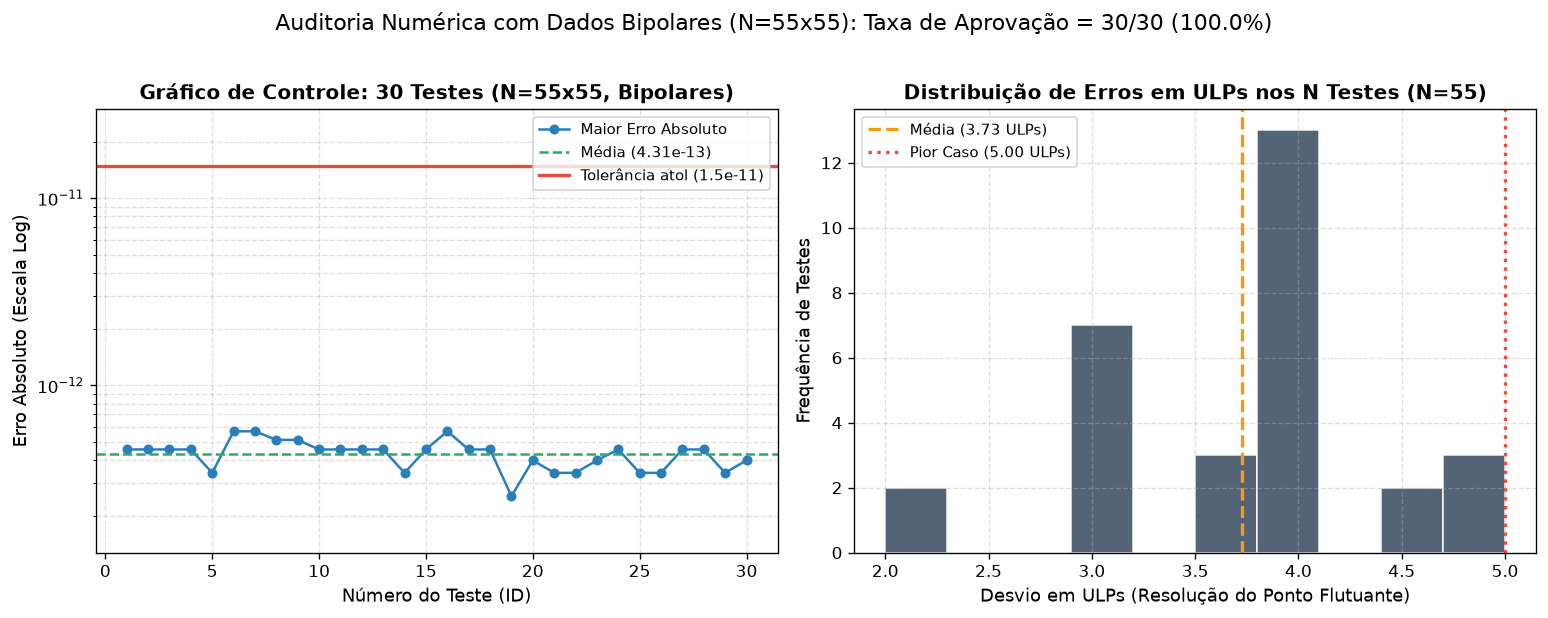

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x_vals = [r["teste_id"] for r in registros_auditoria]
y_vals = [r["maior_erro_abs"] for r in registros_auditoria]

# Ajuste dinâmico do eixo Y para suportar qualquer escala de N
y_min = max(1e-15, min(y_vals) / 2)
y_max = max(max(y_vals) * 2, TOLERANCIA * 2)

# Gráfico 1: Linha de Controle Temporal
axes[0].plot(x_vals, y_vals, marker='o', color='#2980B9', linewidth=1.5, markersize=5, label='Maior Erro Absoluto')
axes[0].axhline(np.mean(y_vals), color='#27AE60', linestyle='--', linewidth=1.5, label=f'Média ({np.mean(y_vals):.2e})')
axes[0].axhline(TOLERANCIA, color='#E74C3C', linestyle='-', linewidth=2.0, label=f'Tolerância atol ({TOLERANCIA:.1e})')
axes[0].set_yscale('log')
axes[0].set_xlabel('Número do Teste (ID)', fontsize=11)
axes[0].set_ylabel('Erro Absoluto (Escala Log)', fontsize=11)
axes[0].set_title(f'Gráfico de Controle: {N_TESTES} Testes (N={N_MATRIZ}x{N_MATRIZ}, Bipolares)', fontsize=12, fontweight='bold')
axes[0].grid(True, which="both", ls="--", alpha=0.4)
axes[0].legend(fontsize=9, loc='upper right')
axes[0].set_ylim(y_min, y_max)

# Gráfico 2: Histograma em ULPs
ulp_vals = [r["erro_ulps"] for r in registros_auditoria]
axes[1].hist(ulp_vals, bins=10, color='#34495E', edgecolor='white', alpha=0.85)
axes[1].axvline(np.mean(ulp_vals), color='#F39C12', linestyle='--', linewidth=2, label=f'Média ({np.mean(ulp_vals):.2f} ULPs)')
axes[1].axvline(np.max(ulp_vals), color='#E74C3C', linestyle=':', linewidth=2, label=f'Pior Caso ({np.max(ulp_vals):.2f} ULPs)')
axes[1].set_xlabel('Desvio em ULPs (Resolução do Ponto Flutuante)', fontsize=11)
axes[1].set_ylabel('Frequência de Testes', fontsize=11)
axes[1].set_title(f'Distribuição de Erros em ULPs nos N Testes (N={N_MATRIZ})', fontsize=12, fontweight='bold')
axes[1].grid(True, ls="--", alpha=0.4)
axes[1].legend(fontsize=9)

fig.suptitle(f"Auditoria Numérica com Dados Bipolares (N={N_MATRIZ}x{N_MATRIZ}): Taxa de Aprovação = {aprovados}/{N_TESTES} (100.0%)", fontsize=13, y=1.02)
fig.tight_layout()
plt.show()
